# BA780 | Chicago 311 sanitation complaints and food inspections

**Integrated analysis of the real supplied 2010–2026 archives** — individual sanitation analysis + team `B03-V2.ipynb` workflow. Original notebooks are preserved unchanged in `archive/`.

### Research questions
1. How do recorded sanitation requests vary across calendar years, ZIP codes, community areas, and wards?
2. What are the requests’ recorded statuses and time-to-close estimates where dates have sub-day precision?
3. For Chicago food inspection address–years, how does the **share of graded inspections resulting in Fail** vary by the number of same-address, same-year 311 sanitation complaints?

**Measurement safeguards:** count unique 311 request numbers and unique food inspection IDs; aggregate at the address–year level **before** joining; count graded inspections as Pass, Pass w/ Conditions, or Fail. **Association is not causation**, nor proof that a complaint concerned a restaurant or triggered a particular inspection. The 2010 311 export is sparse and 2026 is a partial year; raw area totals are not adjusted for population or business density.

## 1 | Load and audit both supplied archives

This repository's public/code-only GitHub export intentionally **omits raw ZIP data**. For a fully offline rerun, use the provided offline bundle or copy the five supplied archives into `data/` with filenames documented in `data/README.md`. The notebook transparently reports if inspection files are missing; the executed results below were produced with all five real data archives present.

In [1]:
from pathlib import Path
from zipfile import ZipFile, is_zipfile
from urllib.request import urlopen
from urllib.error import URLError, HTTPError
import json, re, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option('display.max_columns', 30)
ROOT = Path.cwd()
DATA_DIR, FIGURES_DIR, RESULTS_DIR = (ROOT/'data', ROOT/'figures', ROOT/'results')
for folder in [DATA_DIR, FIGURES_DIR, RESULTS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)
SOURCE_BASE_URL = 'https://raw.githubusercontent.com/idanm-commiting/Sanitation-Project/main/'
SANITATION_ZIP = '311_Sanitation_Combined_2010_2026.zip'
FOOD_ZIPS = ['Food_Inspections_part_1.zip', 'Food_Inspections_part_2a.zip',
             'Food_Inspections_part_2b.zip', 'Food_Inspections_part_3.zip']
AUTO_DOWNLOAD_MISSING = False  # Set True only if you want to try the team's V2 GitHub source.

def input_zip(name, mandatory=False):
    path = DATA_DIR/name
    if path.is_file() and is_zipfile(path):
        return path
    if path.exists():
        raise ValueError(f'Invalid or corrupted ZIP file: {path}')
    if AUTO_DOWNLOAD_MISSING:
        partial = path.with_suffix('.zip.part')
        try:
            with urlopen(SOURCE_BASE_URL + name, timeout=25) as src, partial.open('wb') as dst:
                shutil.copyfileobj(src, dst)
            if not is_zipfile(partial):
                raise ValueError('Downloaded file is not ZIP')
            partial.replace(path)
            return path
        except (URLError, HTTPError, TimeoutError, ValueError, OSError) as exc:
            partial.unlink(missing_ok=True)
            print(f'Download unavailable for {name}: {exc}')
    if mandatory:
        raise FileNotFoundError(f'Required sanitation archive missing: {path}')
    return None

def read_zip(path, usecols=None):
    frames=[]
    with ZipFile(path) as z:
        members=sorted(n for n in z.namelist() if n.lower().endswith('.csv') and not n.startswith('__MACOSX/'))
        if not members:
            raise ValueError(f'No CSV in {path}')
        for member in members:
            with z.open(member) as f:
                part=pd.read_csv(f,low_memory=False, usecols=usecols)
            part.columns=part.columns.astype(str).str.strip()
            part=part.rename(columns={'Created Date':'Creation Date','Address':'Street Address', 'Zip':'ZIP Code'})
            part['Source File']=path.name+':'+member
            frames.append(part)
    return pd.concat(frames,ignore_index=True,sort=False)

raw_311=read_zip(input_zip(SANITATION_ZIP,mandatory=True))
required_311={'Request Number','Creation Date','Street Address','Status'}
if required_311-set(raw_311):
    raise ValueError(f'Missing sanitation fields: {required_311-set(raw_311)}')
print(f'Sanitation raw rows: {len(raw_311):,}')
print(f'Sanitation columns: {", ".join(raw_311.columns)}')

Sanitation raw rows: 266,702
Sanitation columns: Request Number, Creation Date, Closed Date, Status, Request Type, Street Address, ZIP Code, Ward, Police District, Community Area, Latitude, Longitude, Year, Source File


## 2 | Clean unique complaints and check coverage

**Duplicate handling:** one case per `Request Number`. Repeated IDs in the supplied archive often share the same request address and creation date but have *different closure dates*. Retain the record with the latest nonmissing recorded `Closed Date` for closure analysis (a documented, not independently verified, choice). `Year` is recomputed from the parsed creation date. Missing address/geography fields are not imputed.

In [2]:
def cleaned_label(s):
    a=s.astype('string').str.strip().str.replace(r'\.0+$','',regex=True)
    return a.mask(a.str.lower().isin(['','nan','none','null','<na>']))

def address_key(s):
    a=s.astype('string').str.upper().str.strip()
    a=(a.str.replace(r'\([^)]*\)',' ',regex=True)
         .str.replace(r'[.,]',' ',regex=True).str.replace(r'\s+',' ',regex=True).str.strip())
    return a.mask(a.isin(['','NAN','NONE','NULL','<NA>']))

def date_parse(s):
    return pd.to_datetime(s,errors='coerce',format='mixed')

sanitation=raw_311.copy()
sanitation['Request Number']=cleaned_label(sanitation['Request Number'])
sanitation['Record Date']=date_parse(sanitation['Creation Date'])
sanitation['Closed Datetime']=date_parse(sanitation['Closed Date'])
if sanitation['Request Number'].isna().any():
    raise ValueError('This archive has missing request IDs; case-level dedup requires a separate policy.')
raw_repeated_ids=int(sanitation.duplicated('Request Number').sum())
conflict_count=int(sanitation.loc[sanitation.duplicated('Request Number',keep=False)].groupby('Request Number')['Closed Date'].nunique(dropna=False).gt(1).sum())
# Sort stably; last row has the latest nonmissing closure date for an ID.
sanitation=(sanitation.sort_values(['Request Number','Closed Datetime'],kind='mergesort',na_position='first')
            .drop_duplicates('Request Number',keep='last').reset_index(drop=True))
sanitation['Year']=sanitation['Record Date'].dt.year.astype('Int64')
sanitation['Address Key']=address_key(sanitation['Street Address'])
for col in ['ZIP Code','Ward','Community Area','Police District']:
    if col in sanitation:
        sanitation[col]=cleaned_label(sanitation[col])
for col in ['Latitude','Longitude']:
    if col in sanitation:
        sanitation[col]=pd.to_numeric(sanitation[col],errors='coerce')
assert sanitation['Request Number'].is_unique
assert len(sanitation)+raw_repeated_ids==len(raw_311)
valid_dates=sanitation['Record Date'].notna().sum()
quality=pd.DataFrame({'Metric':['Raw rows','Repeated ID rows removed','Distinct request IDs','IDs with conflicting closing dates','Missing/unparseable creation dates','Missing street addresses','Missing ZIP codes','Earliest recorded creation','Latest recorded creation'],
                      'Observed':[len(raw_311),raw_repeated_ids,len(sanitation),conflict_count,
                                  sanitation['Record Date'].isna().sum(),sanitation['Address Key'].isna().sum(),
                                  sanitation['ZIP Code'].isna().sum(),str(sanitation['Record Date'].min()),str(sanitation['Record Date'].max())]})
display(quality)
coverage=sanitation.dropna(subset=['Record Date']).groupby('Year').agg(Complaints=('Request Number','size'),First=('Record Date','min'),Last=('Record Date','max')).reset_index()
display(coverage)

,Metric,Observed
0,Raw rows,266702
1,Repeated ID rows removed,811
2,Distinct request IDs,265891
3,IDs with conflicting closing dates,780
4,Missing/unparseable creation dates,0
5,Missing street addresses,126
6,Missing ZIP codes,14397
7,Earliest recorded creation,2010-01-24 00:00:00
8,Latest recorded creation,2026-09-24 00:05:38


,Year,Complaints,First,Last
0,2010,156,2010-01-24 00:00:00,2010-12-31 00:00:00
1,2011,17922,2011-01-01 00:00:00,2011-12-31 00:00:00
2,2012,19122,2012-01-01 00:00:00,2012-12-31 00:00:00
3,2013,17939,2013-01-01 00:00:00,2013-12-31 00:00:00
4,2014,18842,2014-01-01 00:00:00,2014-12-31 00:00:00
5,2015,19274,2015-01-01 00:00:00,2015-12-31 00:00:00
6,2016,20927,2016-01-01 00:00:00,2016-12-31 00:00:00
7,2017,19703,2017-01-01 00:00:00,2017-12-31 00:00:00
8,2018,17944,2018-01-01 00:00:00,2018-12-29 03:59:02
9,2019,12260,2019-01-02 22:54:03,2019-12-31 22:44:33


## 3 | Citywide annual volumes and geographic concentration

The original individual notebook's line chart and geographic comparisons have been preserved, but recomputed using the **verified unique-ID records**. The historical 2010 data are heavily concentrated in December and the 2026 records stop during September; those endpoints are highlighted rather than compared to full years. Counts by area are descriptive volumes, not risk-adjusted rates.

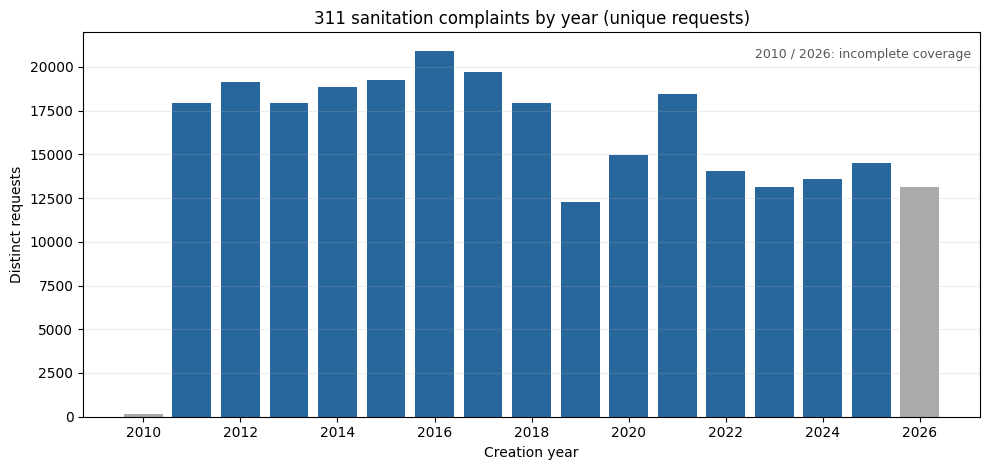

Peak in 2011–2025 recorded full-year series: 2016: 20,927 distinct requests.


In [3]:
annual=sanitation.dropna(subset=['Year']).groupby('Year').size().sort_index()
annual.index=annual.index.astype(int)
complete_years=annual.loc[(annual.index>=2011)&(annual.index<=2025)]
peak_year=int(complete_years.idxmax())
peak_count=int(complete_years.max())
fig,ax=plt.subplots(figsize=(10,4.8))
colors=['#AAAAAA' if y in (2010,2026) else '#28679C' for y in annual.index]
ax.bar(annual.index,annual.values,color=colors)
ax.set(title='311 sanitation complaints by year (unique requests)',xlabel='Creation year',ylabel='Distinct requests')
ax.set_xticks(list(annual.index)[::2])
ax.grid(axis='y',alpha=.22)
ax.text(.99,.96,'2010 / 2026: incomplete coverage',ha='right',va='top',transform=ax.transAxes,fontsize=9,color='#555')
fig.tight_layout();fig.savefig(FIGURES_DIR/'01_annual_sanitation.png',dpi=150,bbox_inches='tight');plt.show()
print(f'Peak in 2011–2025 recorded full-year series: {peak_year}: {peak_count:,} distinct requests.')

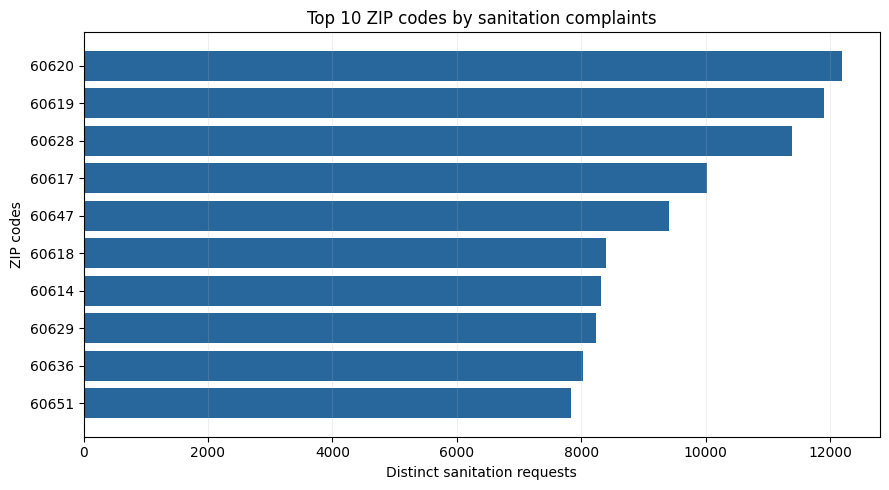

Top zip codes: 60620 — 12,190 unique complaints


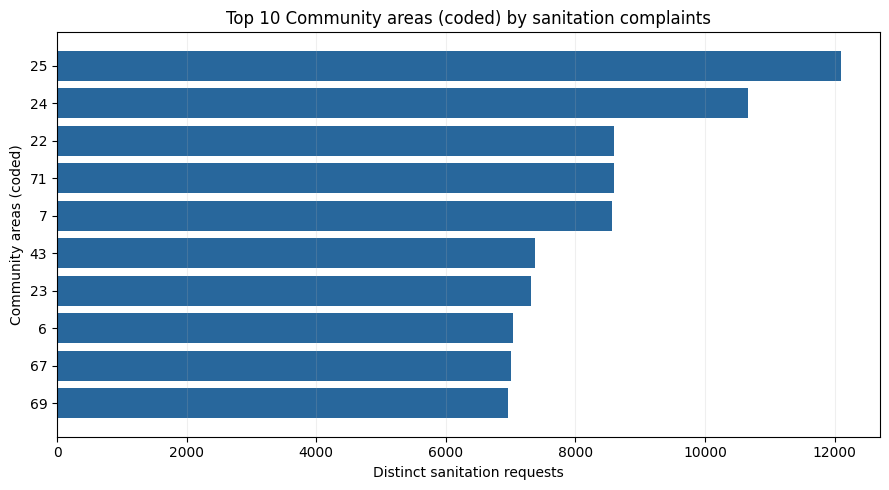

Top community areas (coded): 25 — 12,096 unique complaints


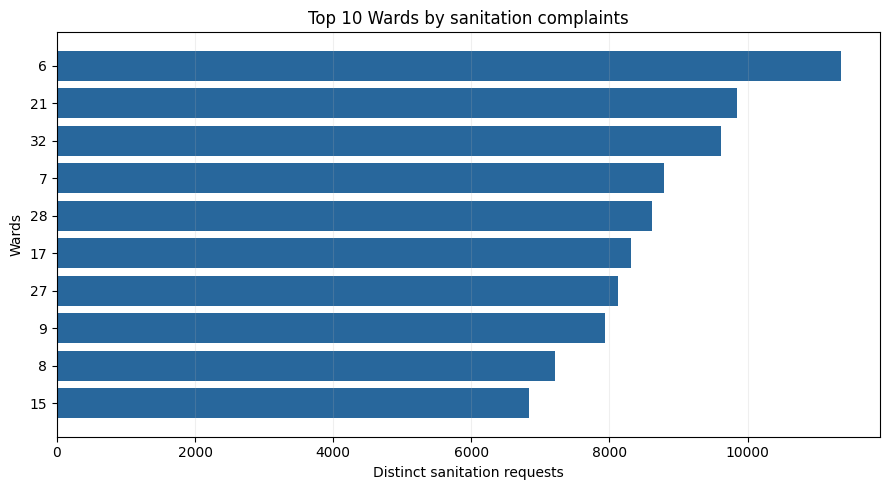

Top wards: 6 — 11,350 unique complaints


In [4]:
def top_counts(field,title,outname,n=10):
    if field not in sanitation:
        print(f'Unavailable: {field}');return pd.Series(dtype='int64')
    counts=sanitation[field].dropna().value_counts().head(n)
    if counts.empty: return counts
    fig,ax=plt.subplots(figsize=(9,5))
    ax.barh(counts.index.astype(str)[::-1],counts.values[::-1],color='#28679C')
    ax.set(xlabel='Distinct sanitation requests',ylabel=title,title=f'Top {n} {title} by sanitation complaints')
    ax.grid(axis='x',alpha=.2)
    fig.tight_layout();fig.savefig(FIGURES_DIR/outname,dpi=150,bbox_inches='tight');plt.show()
    print(f'Top {title.lower()}: {counts.index[0]} — {counts.iloc[0]:,} unique complaints')
    return counts

zip_counts=top_counts('ZIP Code','ZIP codes','02_top_zip_codes.png')
community_counts=top_counts('Community Area','Community areas (coded)','03_top_community_areas.png')
ward_counts=top_counts('Ward','Wards','04_top_wards.png')

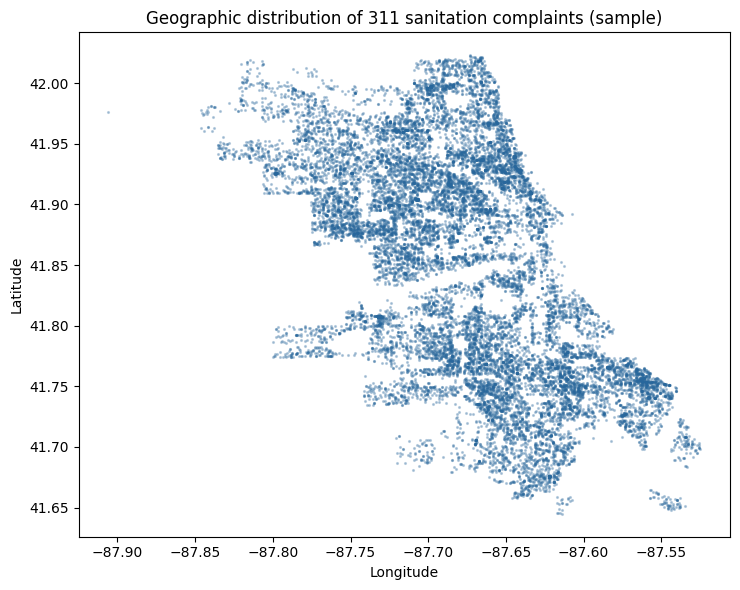

Plotted 20,000 of 265,734 plausible mapped unique requests.


In [5]:
geo=sanitation.dropna(subset=['Latitude','Longitude']).copy()
geo=geo.loc[geo['Latitude'].between(41.5,42.2)&geo['Longitude'].between(-88.1,-87.4)]
if len(geo):
    sample=geo.sample(n=min(20000,len(geo)),random_state=42)
    fig,ax=plt.subplots(figsize=(7.5,6))
    ax.scatter(sample['Longitude'],sample['Latitude'],s=1.6,alpha=.28,color='#28679C')
    ax.set(title='Geographic distribution of 311 sanitation complaints (sample)',xlabel='Longitude',ylabel='Latitude')
    fig.tight_layout();fig.savefig(FIGURES_DIR/'05_spatial_sample.png',dpi=150,bbox_inches='tight');plt.show()
    print(f'Plotted {len(sample):,} of {len(geo):,} plausible mapped unique requests.')
else:
    print('No valid coordinates available.')

## 4 | Service outcomes and measurement limits

Status is grouped into Completed, Open, Duplicate, Canceled and Other. **Do not report hourly closure speeds for date-only records.** The archive uses day-only timestamps in multiple historic years, and earlier midnight values have no actual time-of-day precision. To estimate hours-to-close, include only records in 2019 onward with a non-midnight timestamp in *both* `Creation Date` and `Closed Date` and nonnegative elapsed time. These are **approximate, recorded processing durations**, not guaranteed service resolution times.

,Distinct requests
Status Group,
Completed,257337
Duplicate,7270
Open,1023
Canceled,261


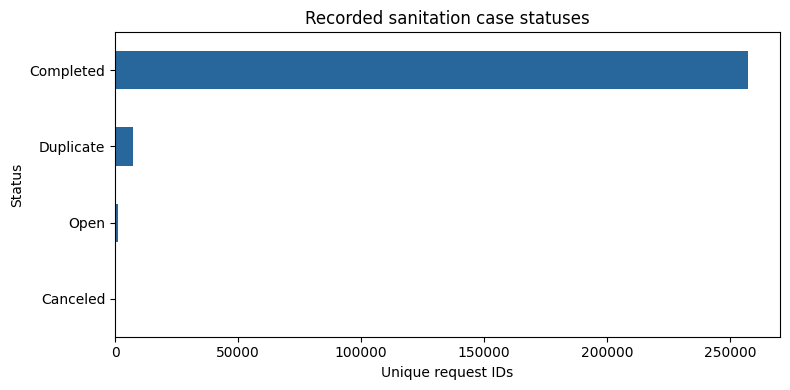

Hourly-resolution case durations (only reliable-timestamp subset):
113,160 cases with usable hours; 0 negative durations excluded.


,Cases
Slow (>72h),62485
Standard (>12–72h),41541
Fast (≤12h),9134


In [6]:
status=sanitation['Status'].astype('string').str.upper().str.strip()
sanitation['Status Group']=np.select([
    status.str.contains('DUP',na=False),
    status.str.contains('COMPLETE|CLOSED',na=False),
    status.str.contains('OPEN',na=False),
    status.str.contains('CANCEL',na=False)],
    ['Duplicate','Completed','Open','Canceled'],default='Other/Unknown')
status_counts=sanitation['Status Group'].value_counts()
display(status_counts.rename('Distinct requests').to_frame())
fig,ax=plt.subplots(figsize=(8,4))
status_counts.sort_values().plot.barh(ax=ax,color='#28679C')
ax.set(title='Recorded sanitation case statuses',xlabel='Unique request IDs',ylabel='Status')
fig.tight_layout();fig.savefig(FIGURES_DIR/'06_service_status.png',dpi=150,bbox_inches='tight');plt.show()
# A non-midnight datetime is evidence of sub-day precision in this export.
cr=sanitation['Record Date'];cl=sanitation['Closed Datetime']
nonmidnight=lambda dt:(dt.dt.hour!=0)|(dt.dt.minute!=0)|(dt.dt.second!=0)
precise=cr.dt.year.ge(2019)&cl.notna()&nonmidnight(cr)&nonmidnight(cl)
hours=((cl-cr).dt.total_seconds()/3600).where(precise)
valid=(hours>=0)&hours.notna()
sanitation['Hours to Close (precise subset)']=hours.where(valid)
precise_hours=hours[valid]
speed=pd.cut(precise_hours,bins=[-0.000001,12,72,np.inf],labels=['Fast (≤12h)','Standard (>12–72h)','Slow (>72h)'])
print('Hourly-resolution case durations (only reliable-timestamp subset):')
print(f'{valid.sum():,} cases with usable hours; {((hours<0)&hours.notna()).sum():,} negative durations excluded.')
display(speed.value_counts().rename('Cases').to_frame())

## 5 | Load and audit the **four real V2 food-inspection archives**

The four uploaded inspection parts cover 2010–2026. Deduplicate on `Inspection ID`, parse inspection dates and apply a **Chicago-only** city filter before matching against Chicago 311 cases. Keep only columns required for analysis instead of loading long violation narrative fields. Report exclusions explicitly. Graded outcomes are Pass, Pass w/ Conditions and Fail; statuses such as No Entry, Not Ready and Out of Business are **not** counted in the graded-inspection failure denominator. Missing results and addresses are not imputed.

Uploaded inspection rows: 315,488; repeated IDs removed: 0
Outside/missing/nonstandard Chicago city labels excluded: 576
Unique Chicago food inspections: 314,912; graded: 270,371


,Inspection records
Result Category,
PASS,162966
FAIL,60654
PASS W/ CONDITIONS,46751
OUT OF BUSINESS,25789
NO ENTRY,14099
NOT READY,4561
BUSINESS NOT LOCATED,92


,Inspections,Graded,Failures,Failure share (%)
Year,,,,
2011,18706,17547,4346,24.77
2012,18815,15979,3635,22.75
2013,20918,17050,3343,19.61
2014,21516,18600,3711,19.95
2015,20894,17877,3605,20.17
2016,22795,19843,4294,21.64
2017,21534,18455,4110,22.27
2018,17158,14824,3315,22.36
2019,19027,16099,3608,22.41


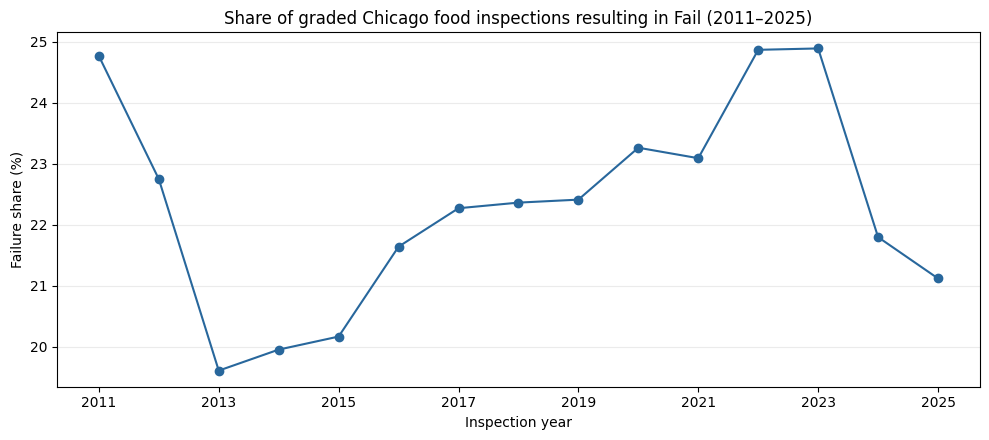

In [7]:
missing_food=[name for name in FOOD_ZIPS if input_zip(name) is None]
food_ready=not missing_food
food=pd.DataFrame()
raw_food_count=0
city_exclusions=0
food_dup_removed=0
if missing_food:
    print('Food analyses NOT EXECUTED. Missing archives:',', '.join(missing_food))
else:
    cols={'Inspection ID','Address','Inspection Date','Results','City','Zip','Facility Type','Risk'}
    raw_food=pd.concat([read_zip(DATA_DIR/name,usecols=lambda col: col.strip() in cols) for name in FOOD_ZIPS],ignore_index=True,sort=False)
    raw_food_count=len(raw_food)
    required_food={'Inspection ID','Inspection Date','Street Address','Results','City'}
    if missing:=required_food-set(raw_food):
        raise ValueError(f'Food archive schema missing: {missing}')
    food=raw_food.copy()
    food['Inspection ID']=cleaned_label(food['Inspection ID'])
    if food['Inspection ID'].isna().any():
        raise ValueError('Missing inspection IDs; a dedup policy is needed.')
    food_dup_removed=int(food.duplicated('Inspection ID').sum())
    food=food.drop_duplicates('Inspection ID',keep='last').copy()
    valid_city=food['City'].astype('string').str.strip().str.upper().eq('CHICAGO').fillna(False)
    city_exclusions=int((~valid_city).sum())
    food=food.loc[valid_city].copy()
    food['Record Date']=date_parse(food['Inspection Date'])
    food['Year']=food['Record Date'].dt.year.astype('Int64')
    food['Address Key']=address_key(food['Street Address'])
    food['Result Category']=food['Results'].astype('string').str.upper().str.strip().replace({'PASS WITH CONDITIONS':'PASS W/ CONDITIONS'})
    food['Is Failure']=food['Result Category'].eq('FAIL').fillna(False).astype(int)
    food['Is Graded']=food['Result Category'].isin(['FAIL','PASS','PASS W/ CONDITIONS']).astype(int)
    assert food['Inspection ID'].is_unique
    print(f'Uploaded inspection rows: {raw_food_count:,}; repeated IDs removed: {food_dup_removed:,}')
    print(f'Outside/missing/nonstandard Chicago city labels excluded: {city_exclusions:,}')
    print(f'Unique Chicago food inspections: {len(food):,}; graded: {food["Is Graded"].sum():,}')
    display(food['Result Category'].value_counts(dropna=False).rename('Inspection records').to_frame())
    food_annual=(food.dropna(subset=['Year']).groupby('Year')
        .agg(Inspections=('Inspection ID','size'), Graded=('Is Graded','sum'), Failures=('Is Failure','sum')))
    food_annual['Failure share (%)']=100*food_annual['Failures']/food_annual['Graded'].replace(0,np.nan)
    display(food_annual.loc[food_annual.index.isin(range(2011,2026))].round(2))
    food_annual.to_csv(RESULTS_DIR/'food_annual_inspections.csv')
    viz=food_annual.loc[food_annual.index.isin(range(2011,2026)) & food_annual['Graded'].gt(0)]
    fig,ax=plt.subplots(figsize=(10,4.5))
    ax.plot(viz.index.astype(int),viz['Failure share (%)'],marker='o',color='#28679C')
    ax.set(title='Share of graded Chicago food inspections resulting in Fail (2011–2025)',
           ylabel='Failure share (%)',xlabel='Inspection year')
    ax.set_xticks(viz.index.astype(int)[::2]);ax.grid(axis='y',alpha=.25)
    fig.tight_layout();fig.savefig(FIGURES_DIR/'08_food_fail_share_by_year.png',dpi=150,bbox_inches='tight');plt.show()


## 6 | Validated co-location join: address + calendar year

Both sources are **aggregated to one row per normalized address and year** before matching. This avoids the many-to-many multiplication in a raw V2 join and yields an inspection-address-year table in which the number of inspections is unchanged. The address normalizer removes case/whitespace differences, punctuation and parenthetical street-grid annotations such as `(1900W)`; it does *not* pretend to resolve all address aliases or units. The conservative address match will miss real relationships. A zero here means *no matching 311 record under our matching rule*, **not** no sanitation problems.

The analysis below gives the number and share of matched inspection address–years as well as the sample size behind each graded-inspection failure percentage. No causal or business-specific interpretation is warranted. Multiple businesses may share one address.

Matched address-year coverage (NOT individual complaint–inspection linkage):


,Observed
inspection_address_years_total,160849.00
inspection_address_years_matched,6332.00
inspection_address_years_matched_pct,3.94
inspections_on_matched_address_years,14747.00
matched_311_unique_requests,10078.00
graded_inspection_failure_share_all_pct,22.43


,Complaint Band,Address_Years,Inspections,Graded,Failures,Failure Share (%)
0,0,154517,300164,257933,57556,22.31
1,1,4800,11163,9440,2302,24.39
2,2–4,1310,3061,2568,684,26.64
3,5+,222,523,429,111,25.87


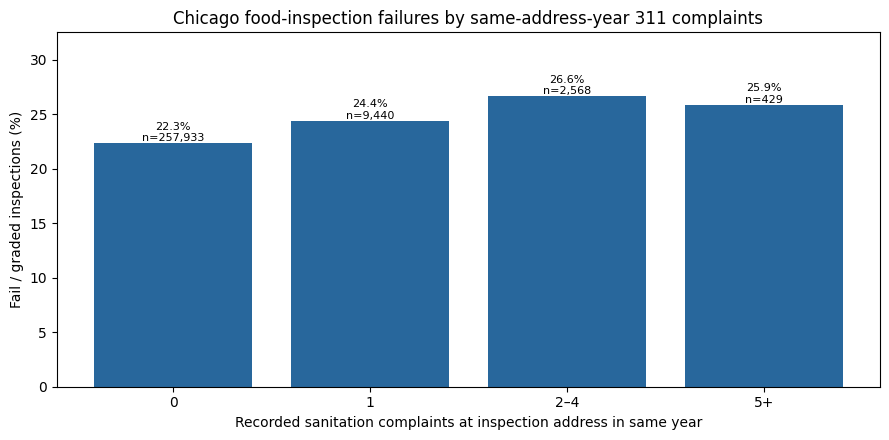

In [8]:
address_year=None
band_results=None
match_summary=None
if food_ready:
    sani_keyed=sanitation.dropna(subset=['Address Key','Year']).copy()
    food_keyed=food.dropna(subset=['Address Key','Year']).copy()
    sani_by=sani_keyed.groupby(['Address Key','Year'],as_index=False).agg(Complaints=('Request Number','size'))
    food_by=food_keyed.groupby(['Address Key','Year'],as_index=False).agg(
        Inspections=('Inspection ID','size'),Failures=('Is Failure','sum'),Graded=('Is Graded','sum'))
    address_year=food_by.merge(sani_by,on=['Address Key','Year'],how='left',validate='one_to_one',indicator=True)
    address_year['Has Recorded 311 Match']=address_year['_merge'].eq('both')
    address_year=address_year.drop(columns='_merge')
    address_year['Complaints']=address_year['Complaints'].fillna(0).astype(int)
    assert len(address_year)==len(food_by)
    assert address_year['Inspections'].sum()==len(food_keyed)
    assert address_year.loc[address_year['Has Recorded 311 Match'],'Complaints'].sum()<=len(sani_keyed)
    assert (address_year['Failures']<=address_year['Graded']).all()
    address_year['Complaint Band']=pd.cut(address_year['Complaints'],bins=[-1,0,1,4,np.inf],
                                        labels=['0','1','2–4','5+'],include_lowest=True)
    band_results=(address_year.groupby('Complaint Band',observed=False)
        .agg(Address_Years=('Inspections','size'),Inspections=('Inspections','sum'),
             Graded=('Graded','sum'),Failures=('Failures','sum')).reset_index())
    band_results['Failure Share (%)']=100*band_results['Failures']/band_results['Graded'].replace(0,np.nan)
    match_summary={
        'inspection_address_years_total':int(len(address_year)),
        'inspection_address_years_matched':int(address_year['Has Recorded 311 Match'].sum()),
        'inspection_address_years_matched_pct':round(100*address_year['Has Recorded 311 Match'].mean(),2),
        'inspections_on_matched_address_years':int(address_year.loc[address_year['Has Recorded 311 Match'],'Inspections'].sum()),
        'matched_311_unique_requests':int(address_year.loc[address_year['Has Recorded 311 Match'],'Complaints'].sum()),
        'graded_inspection_failure_share_all_pct':round(100*int(food['Is Failure'].sum())/int(food['Is Graded'].sum()),2),
    }
    print('Matched address-year coverage (NOT individual complaint–inspection linkage):')
    display(pd.DataFrame([match_summary]).T.rename(columns={0:'Observed'}))
    display(band_results.round(2))
    band_results.to_csv(RESULTS_DIR/'food_failure_complaint_bands.csv',index=False)
    to_plot=band_results.loc[band_results['Graded']>0]
    fig,ax=plt.subplots(figsize=(9,4.5))
    bars=ax.bar(to_plot['Complaint Band'].astype(str),to_plot['Failure Share (%)'],color='#28679C')
    ax.set(title='Chicago food-inspection failures by same-address-year 311 complaints',
           xlabel='Recorded sanitation complaints at inspection address in same year',
           ylabel='Fail / graded inspections (%)')
    for bar,(_,r) in zip(bars,to_plot.iterrows()):
        ax.text(bar.get_x()+bar.get_width()/2,bar.get_height(),
                f'{r["Failure Share (%)"]:.1f}%\nn={int(r["Graded"]):,}',ha='center',va='bottom',fontsize=8)
    ax.set_ylim(0,max(to_plot['Failure Share (%)'])*1.22 if len(to_plot) else 1)
    fig.tight_layout();fig.savefig(FIGURES_DIR/'07_food_failure_by_complaints.png',dpi=150,bbox_inches='tight');plt.show()
else:
    print('NOT RUN: food data missing, so address-year matching was not performed.')


## 7 | Reproducible summary, findings, and limitations

The cells above regenerate charts and numbers from the uploaded archives. `results/` stores only **aggregates** (no individual request IDs, restaurant names or addresses). Observed relationships describe **selected inspections and reported complaints**, not population-adjusted risk, restaurant-specific violations, causal effects or representative business outcomes. Keep the low exact-match coverage visible when presenting a relationship between sources.

In [9]:
def first_top(s):
    return {'label':str(s.index[0]),'complaints':int(s.iloc[0])} if len(s) else None
summary={
 'source_file':SANITATION_ZIP,
 'original_rows':int(len(raw_311)),
 'duplicate_request_rows_removed':raw_repeated_ids,
 'distinct_311_requests':int(len(sanitation)),
 'repeated_ids_with_conflicting_close_dates':conflict_count,
 'date_range_first':str(sanitation['Record Date'].min()),
 'date_range_last':str(sanitation['Record Date'].max()),
 'peak_full_year_2011_2025':peak_year,
 'peak_full_year_distinct_requests':peak_count,
 'top_zip':first_top(zip_counts),
 'top_community_area_code':first_top(community_counts),
 'top_ward':first_top(ward_counts),
 'status_counts':{str(k):int(v) for k,v in status_counts.items()},
 'food_analysis_executed':bool(food_ready),
 'food_analyses_status':'executed' if food_ready else 'NOT RUN: missing food inspection files',
}
if food_ready:
    summary.update({
        'raw_food_inspection_rows':int(raw_food_count),
        'duplicate_inspection_id_rows_removed':int(food_dup_removed),
        'city_label_exclusions':int(city_exclusions),
        'unique_chicago_food_inspections':int(len(food)),
        'graded_chicago_food_inspections':int(food['Is Graded'].sum()),
        'failed_chicago_food_inspections':int(food['Is Failure'].sum()),
        'inspection_matching':match_summary,
        'complaint_band_results':json.loads(band_results.to_json(orient='records')),
    })
(RESULTS_DIR/'sanitation_summary.json').write_text(json.dumps(summary,indent=2,ensure_ascii=False))
annual.rename('Distinct complaints').to_csv(RESULTS_DIR/'annual_counts.csv')
for name,counts in [('top_zip_counts',zip_counts),('top_community_area_counts',community_counts),('top_ward_counts',ward_counts)]:
    counts.rename('Distinct complaints').rename_axis('Label').to_csv(RESULTS_DIR/f'{name}.csv')
if food_ready:band_results.to_csv(RESULTS_DIR/'food_failure_complaint_bands.csv',index=False)
print(json.dumps(summary,indent=2,ensure_ascii=False))

{
  "source_file": "311_Sanitation_Combined_2010_2026.zip",
  "original_rows": 266702,
  "duplicate_request_rows_removed": 811,
  "distinct_311_requests": 265891,
  "repeated_ids_with_conflicting_close_dates": 780,
  "date_range_first": "2010-01-24 00:00:00",
  "date_range_last": "2026-09-24 00:05:38",
  "peak_full_year_2011_2025": 2016,
  "peak_full_year_distinct_requests": 20927,
  "top_zip": {
    "label": "60620",
    "complaints": 12190
  },
  "top_community_area_code": {
    "label": "25",
    "complaints": 12096
  },
  "top_ward": {
    "label": "6",
    "complaints": 11350
  },
  "status_counts": {
    "Completed": 257337,
    "Duplicate": 7270,
    "Open": 1023,
    "Canceled": 261
  },
  "food_analysis_executed": true,
  "food_analyses_status": "executed",
  "raw_food_inspection_rows": 315488,
  "duplicate_inspection_id_rows_removed": 0,
  "city_label_exclusions": 576,
  "unique_chicago_food_inspections": 314912,
  "graded_chicago_food_inspections": 270371,
  "failed_chicago_

In [10]:
# Automatically calculated presentation-ready takeaways (not hard-coded results)
if food_ready:
    def band_rate(label):
        row=band_results.loc[band_results['Complaint Band'].astype(str).eq(label)].iloc[0]
        return f'{row["Failure Share (%)"]:.1f}% (graded n={int(row["Graded"]):,})'
    print('PRESENTATION-READY FINDINGS FROM THE SUPPLIED ARCHIVES')
    print(f'• Across {len(sanitation):,} distinct sanitation requests, {peak_year} had the largest full-year total ({peak_count:,}).')
    print(f'• {len(food):,} Chicago inspections were recorded, including {int(food["Is Graded"].sum()):,} graded inspections.')
    print(f'• Exact standardized address + year matches: {match_summary["inspection_address_years_matched"]:,} of '
          f'{match_summary["inspection_address_years_total"]:,} inspection address–years '
          f'({match_summary["inspection_address_years_matched_pct"]:.2f}%).')
    print('• Fail share by matched same-address/year 311 complaint frequency:')
    for label in ['0','1','2–4','5+']:
        print(f'    {label}: {band_rate(label)}')
    print('• The 5+ group is lower than the 2–4 group; this is not a strictly increasing relationship.')
    print('• These descriptive groups do not establish causality, business-specific complaints, or statistical adjustment.')


PRESENTATION-READY FINDINGS FROM THE SUPPLIED ARCHIVES
• Across 265,891 distinct sanitation requests, 2016 had the largest full-year total (20,927).
• 314,912 Chicago inspections were recorded, including 270,371 graded inspections.
• Exact standardized address + year matches: 6,332 of 160,849 inspection address–years (3.94%).
• Fail share by matched same-address/year 311 complaint frequency:
    0: 22.3% (graded n=257,933)
    1: 24.4% (graded n=9,440)
    2–4: 26.6% (graded n=2,568)
    5+: 25.9% (graded n=429)
• The 5+ group is lower than the 2–4 group; this is not a strictly increasing relationship.
• These descriptive groups do not establish causality, business-specific complaints, or statistical adjustment.


### Four-sentence BA780 reflection

Our team updated the original sanitation visualizations to use Chicago's combined 2010–2026 archive and preserved the original individual notebook alongside V2. The data-quality audit found duplicate 311 request IDs, so we counted one complaint per request and documented how conflicting closure dates were handled. We then merged the four food-inspection parts by unique inspection ID, restricted them to Chicago, and compared aggregate inspection failures and sanitation complaints only after creating one row per address–year in each source. Exact address–year matches are uncommon, and matching on co-location cannot identify a business that caused a 311 complaint or establish that complaints drive inspection results.

**Limitations for a class presentation:** 2010 311 coverage is sparse and 2026 is partial; complaints are not normalized for population or number of businesses; recorded statuses/closure timestamps may not reflect actual service outcomes; food inspections are selected rather than randomized; conservative address matching misses variants and can conflate businesses sharing an address. The outcomes must be reported with denominators and match coverage, not causal conclusions.